# Week 3 · Part C — Prove the palette, do not claim it

This audit compares Matplotlib `tab10`'s first four colors with the course's three-color palette plus its fourth slot. The swatch sheet shows the original palette and Machado severity-1.0 simulations for deutan, protan, and tritan vision. Perceptual separation is then checked numerically with `vizlib.worst_pair()` in OKLab.

In [3]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import to_hex
from matplotlib.patches import Rectangle

WEEK3_DIR = next(
    path for path in (Path.cwd(), Path.cwd() / "week3", Path.cwd().parent / "week3")
    if (path / "assignments" / "vizlib.py").is_file()
)
ASSIGNMENTS_DIR = WEEK3_DIR / "assignments"
sys.path.insert(0, str(ASSIGNMENTS_DIR))

from vizlib import PALETTE, simulate_cvd, style_defaults, verdict, worst_pair

style_defaults()
MY_PALETTE = [to_hex(color) for color in plt.get_cmap("tab10").colors[:4]]
MY_LABEL = "Matplotlib tab10 (first four)"
COURSE_PALETTE = PALETTE["series"] + [PALETTE["series_4th"]]
PALETTES = [
    (MY_PALETTE, MY_LABEL),
    (COURSE_PALETTE, "Course palette + fourth slot"),
]
KINDS = ["normal", "deutan", "protan", "tritan"]

print(f"Comparison palette: {MY_PALETTE}")
print(f"Course palette:     {COURSE_PALETTE}")

Comparison palette: ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
Course palette:     ['#0072B2', '#D55E00', '#009E73', '#CC79A7']


## C1–C2 · Simulated swatches

Each row shows one palette under normal vision and three Machado severity-1.0 simulations. The swatches retain their slot labels so a pair can be traced into the numeric audit.

Saved 300 dpi swatch sheet: d:\7_Semester\data-visualization\week3\assignments\partC_palette.png


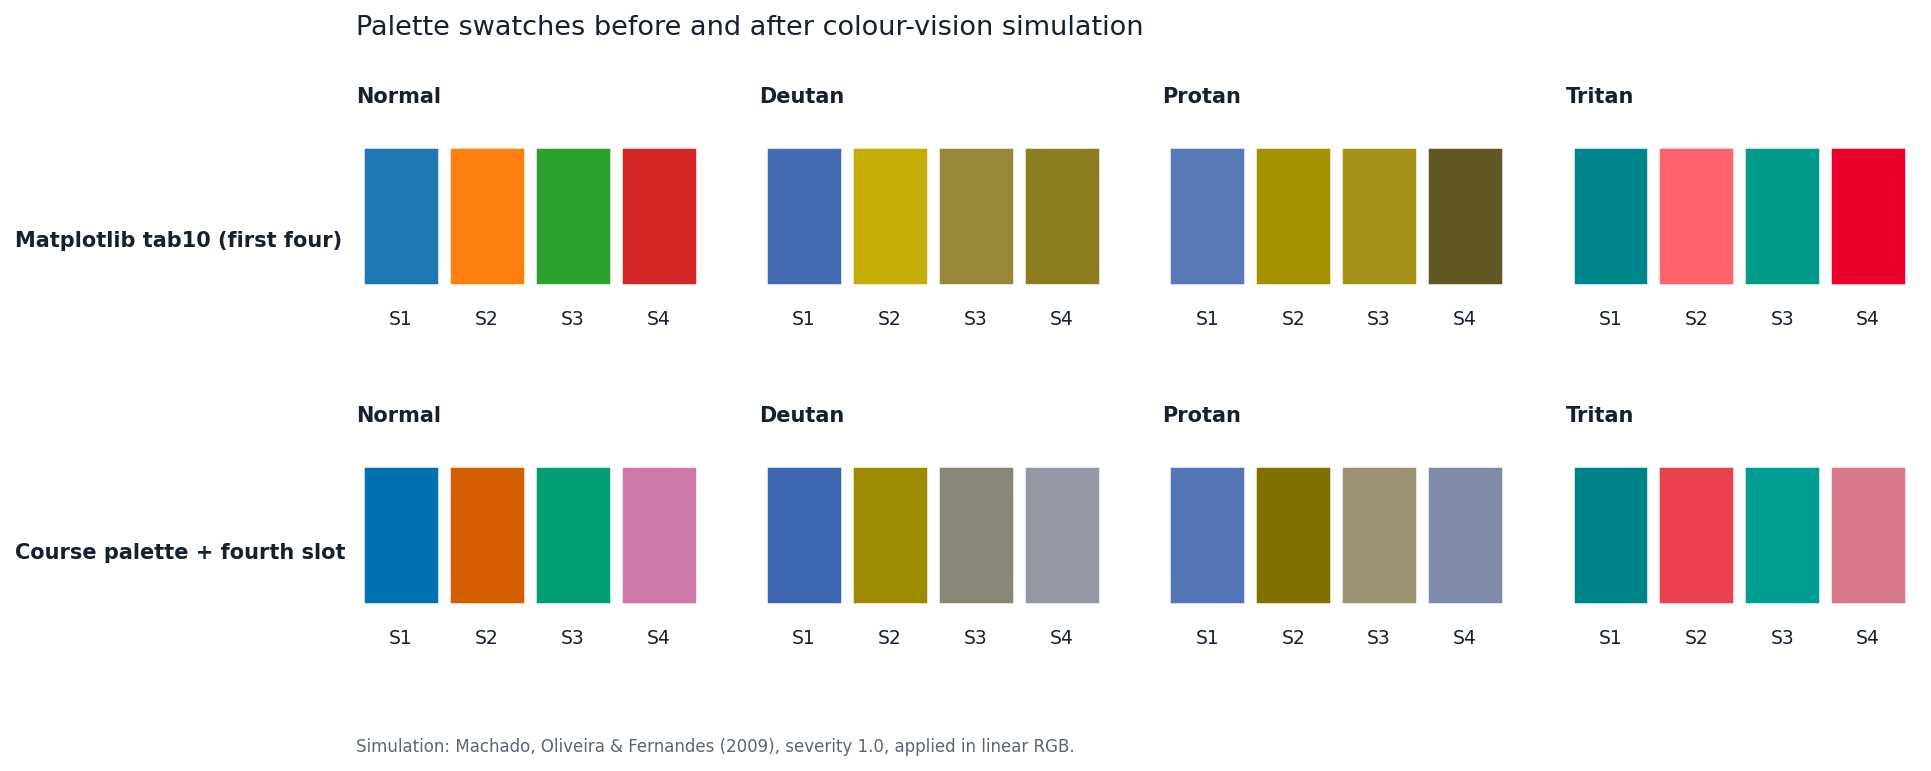

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(13, 5.2))
for row, (palette, label) in enumerate(PALETTES):
    for column, kind in enumerate(KINDS):
        ax = axes[row, column]
        shown = palette if kind == "normal" else simulate_cvd(palette, kind)
        for slot, color in enumerate(shown):
            ax.add_patch(Rectangle((slot, 0), 0.88, 0.9, facecolor=color, edgecolor="#FFFFFF", linewidth=1.2))
            ax.text(slot + 0.44, -0.16, f"S{slot + 1}", ha="center", va="top", fontsize=9)
        ax.set_xlim(-0.08, len(palette))
        ax.set_ylim(-0.38, 1.05)
        ax.set_title(kind.title(), fontsize=10)
        ax.axis("off")
    fig.text(0.015, 0.68 - row * 0.4, label, va="center", fontsize=10, fontweight="bold")

fig.suptitle("Palette swatches before and after colour-vision simulation", x=0.19, ha="left", y=0.97, fontsize=13)
fig.text(0.19, 0.025, "Simulation: Machado, Oliveira & Fernandes (2009), severity 1.0, applied in linear RGB.", fontsize=8, color=PALETTE["ink_soft"])
fig.subplots_adjust(left=0.19, right=0.99, top=0.83, bottom=0.14, wspace=0.15, hspace=0.45)
SWATCH_PATH = ASSIGNMENTS_DIR / "partC_palette.png"
fig.savefig(SWATCH_PATH, dpi=300, bbox_inches="tight")
print(f"Saved 300 dpi swatch sheet: {SWATCH_PATH}")
plt.show()

## C3 · Measure the closest pair in each view

`worst_pair()` compares every pair after simulation and reports OKLab ΔE. The course threshold is at least 8 under each color-vision simulation; values from 6 to 8 need a second visual channel, and values below 6 fail.

In [5]:
pair_rows = []
for palette, palette_label in PALETTES:
    for kind in KINDS:
        slot_i, slot_j, color_i, color_j, distance = worst_pair(palette, kind)
        pair_rows.append({
            "palette": palette_label,
            "vision": kind,
            "closest_slots": f"S{slot_i} / S{slot_j}",
            "colors": f"{color_i} / {color_j}",
            "delta_e_oklab": distance,
            "verdict": verdict(distance),
        })
worst_pair_table = pd.DataFrame(pair_rows).set_index(["palette", "vision"])
display(worst_pair_table.round({"delta_e_oklab": 2}))

closest_slots             colors  \
palette                       vision                                    
Matplotlib tab10 (first four) normal       S2 / S4  #ff7f0e / #d62728   
                              deutan       S3 / S4  #2ca02c / #d62728   
                              protan       S2 / S3  #ff7f0e / #2ca02c   
                              tritan       S1 / S3  #1f77b4 / #2ca02c   
Course palette + fourth slot  normal       S2 / S4  #D55E00 / #CC79A7   
                              deutan       S3 / S4  #009E73 / #CC79A7   
                              protan       S1 / S4  #0072B2 / #CC79A7   
                              tritan       S1 / S3  #0072B2 / #009E73   

                                      delta_e_oklab                 verdict  
palette                       vision                                         
Matplotlib tab10 (first four) normal          18.60                   clear  
                              deutan           4.06     FAILS — same colour  
                              protan           0.68     FAILS — same colour  
                              tritan           6.72  needs a second channel  
Course palette + fourth slot  normal          16.42                   clear  
                              deutan           7.55  needs a second channel  
                              protan           9.49                      ok  
                              tritan           8.37                      ok

**C3 findings.** The four-color tab10 choice fails under deutan (S3 green vs S4 red, ΔE = 4.06) and protan (S2 orange vs S3 green, ΔE = 0.68); both are below the toolkit's ΔE 6 failure threshold. Under tritan its closest pair is S1/S3 at ΔE = 6.72, which requires a second channel. The course palette plus its fourth slot has its closest simulated pair under deutan: S3 `#009E73` vs S4 `#CC79A7`, ΔE = 7.55. That is below the course target of 8, so the fourth hue may not carry identity by itself; use it only with direct labels or a table.

## C4 · Rule for more than three categories

I will not solve a category overflow by adding another color. I will keep the three audited course hues for the primary groups and add a redundant channel—direct labels, distinct marker shapes or line styles—or split the comparison into small multiples. If the fourth course hue is unavoidable, it will always be directly labeled or paired with a table; color alone will never identify it.